# Immuno Compass · Notebook 05: Model 1, the Binomial GLM (Day 5)

**Goal:** fit the classic statistics model, read its **odds ratios**, check **overdispersion**, and see how well it
predicts ADA for **drugs it has never seen** (grouped CV).

**Finish line:** odds-ratio table + forest plot, dispersion number, grouped-CV scores vs the naive baseline, a
regularised (L1 / L2) version, and two sensitivity checks. Results saved in `results/` for the Day 13 comparison.

> 🧒 *Simple version:* the GLM is a weighing scale for clues. Each clue gets a weight that pushes the ADA chance up or
> down, and all the weights are added together.

### How the model works (for the presentation)
For cohort *i* with *nᵢ* patients tested and *yᵢ* ADA-positive:

$$y_i \sim \text{Binomial}(n_i, p_i), \qquad \log\frac{p_i}{1-p_i} = \beta_0 + \beta_1 x_{i1} + \dots + \beta_k x_{ik}$$

* **Binomial:** each of the *n* patients is like a coin flip that comes up "ADA" with probability *p*.
* **logit link:** the weighted sum of clues can be any number; the logit squeezes it into a probability between 0 and 1.
* **Odds ratio = e^β:** OR = 2 means "twice the odds of ADA compared with the reference level, holding the other clues fixed".
* Fitting = **maximum likelihood**: an optimiser searches for the β's that make the observed counts most probable.

In [ ]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # Download the project. If the repository is private, Colab asks for a GitHub token
    # (github.com/settings/tokens → fine-grained, read access to immuno-compass).
    !git clone -q https://github.com/shibilshamz/immuno-compass.git /content/immuno-compass 2>/dev/null
    if not Path("/content/immuno-compass").exists():
        from getpass import getpass
        token = getpass("GitHub token: ")
        !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
        del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

In [ ]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import GroupKFold
np.random.seed(42)
warnings.filterwarnings("ignore", message="Found unknown categories")   # expected, see notebook 04

df = im.load_cohorts(ROOT).join(im.load_folds(ROOT)[["fold_grouped", "fold_random"]])
print(df.shape, "| drugs:", df[im.DRUG].nunique())

BLUE, ORANGE, GRAY, INK2, GRID = "#2a78d6", "#eb6834", "#8a8984", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "savefig.dpi": 200, "savefig.bbox": "tight", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID})

(1754, 41) | drugs: 137


## 1 · Fit the GLM on all cohorts (for interpretation)

For *reading* the coefficients we use **unscaled** features, so each odds ratio is in natural units:
categories vs their reference level, flags yes vs no, `start_year` per year, dose and follow-up per one unit of log.

In [ ]:
pre_raw = im.make_preprocessor(scale=False).fit(df)
X = pd.DataFrame(pre_raw.transform(df), columns=pre_raw.get_feature_names_out())
X = sm.add_constant(X)
endog = np.column_stack([df["y"], df["n"] - df["y"]])            # (successes, failures) per cohort

glm = sm.GLM(endog, X, family=sm.families.Binomial()).fit()
print(f"columns: {X.shape[1]} | rank: {np.linalg.matrix_rank(X.values)}  (equal → no duplicated information ✔)")
print(glm.summary().tables[0])

columns: 43 | rank: 43  (equal → no duplicated information ✔)
                 Generalized Linear Model Regression Results                  
Dep. Variable:           ['y1', 'y2']   No. Observations:                 1754
Model:                            GLM   Df Residuals:                     1711
Model Family:                Binomial   Df Model:                           42
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -17288.
Date:                Sat, 10 Oct 2026   Deviance:                       30555.
Time:                        20:50:09   Pearson chi2:                 3.83e+04
No. Iterations:                     7   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         


## 2 · Overdispersion check

If the Binomial assumptions were right, **Pearson χ² / residual df ≈ 1**. Much bigger means cohorts vary more than
coin-flipping allows, and the model's standard errors (and p-values) are **too optimistic**.

In [ ]:
dispersion = glm.pearson_chi2 / glm.df_resid
print(f"dispersion = {dispersion:.1f}   (intercept-only on Day 3 was ≈ 39)")
print(f"→ standard errors should be ≈ √{dispersion:.0f} ≈ {np.sqrt(dispersion):.1f}× wider than the GLM reports")

dispersion = 22.4   (intercept-only on Day 3 was ≈ 39)
→ standard errors should be ≈ √22 ≈ 4.7× wider than the GLM reports


## 3 · Three versions of the uncertainty: why the honest one matters

| Version | Assumes | Problem |
|---|---|---|
| **Naive** | every patient is an independent coin flip | ignores overdispersion → p-values far too small |
| **Quasi-binomial** | inflate all SEs by √dispersion | better, but still treats cohorts of the same drug as independent |
| **Cluster-robust by molecule** | cohorts of the same molecule (incl. biosimilars) may be correlated | ✔ the honest choice here (108 molecules = 108 clusters) |

In [ ]:
fam = sm.families.Binomial()
quasi   = sm.GLM(endog, X, family=fam).fit(scale="X2")
cluster = sm.GLM(endog, X, family=fam).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(df[im.GROUP])[0]})

ci = cluster.conf_int()
OR = pd.DataFrame({
    "odds_ratio": np.exp(glm.params),
    "CI_low": np.exp(ci[0]), "CI_high": np.exp(ci[1]),
    "p_naive": glm.pvalues, "p_quasi": quasi.pvalues, "p_cluster": cluster.pvalues,
}).drop(index="const")
print("features 'significant' at p < 0.05:")
print(f"  naive: {(OR.p_naive < .05).sum()} | quasi-binomial: {(OR.p_quasi < .05).sum()} | cluster-by-molecule: {(OR.p_cluster < .05).sum()}  (of {len(OR)})")
display(OR.style.format({"odds_ratio": "{:.2f}", "CI_low": "{:.2f}", "CI_high": "{:.2f}",
                         "p_naive": "{:.3f}", "p_quasi": "{:.3f}", "p_cluster": "{:.3f}"})
          .apply(lambda r: ["font-weight:bold" if r.p_cluster < .05 else "" for _ in r], axis=1))

features 'significant' at p < 0.05:
  naive: 40 | quasi-binomial: 40 | cluster-by-molecule: 10  (of 42)


,odds_ratio,CI_low,CI_high,p_naive,p_quasi,p_cluster
route_Ophthalmic,0.26,0.06,1.07,0.000,0.000,0.063
route_Other,0.40,0.13,1.26,0.000,0.000,0.119
route_Subcutaneous,1.37,0.83,2.25,0.000,0.000,0.222
indication_Cardiovascular,3.65,0.83,16.12,0.000,0.000,0.088
indication_Healthy Volunteer,0.31,0.11,0.88,0.000,0.000,0.027
indication_Inflammation and autoimmunity,1.46,0.76,2.83,0.000,0.000,0.260
indication_Musculoskeletal,1.12,0.30,4.19,0.130,0.069,0.862
indication_Neurological,1.15,0.46,2.86,0.002,0.000,0.771
indication_Other,1.13,0.46,2.80,0.046,0.017,0.790
blinding_Open Label,1.18,0.71,1.96,0.000,0.000,0.528


### Forest plot: odds ratios with cluster-robust 95 % intervals
Right of the line = more ADA than the reference; left = less. An interval crossing 1 means "can't tell".

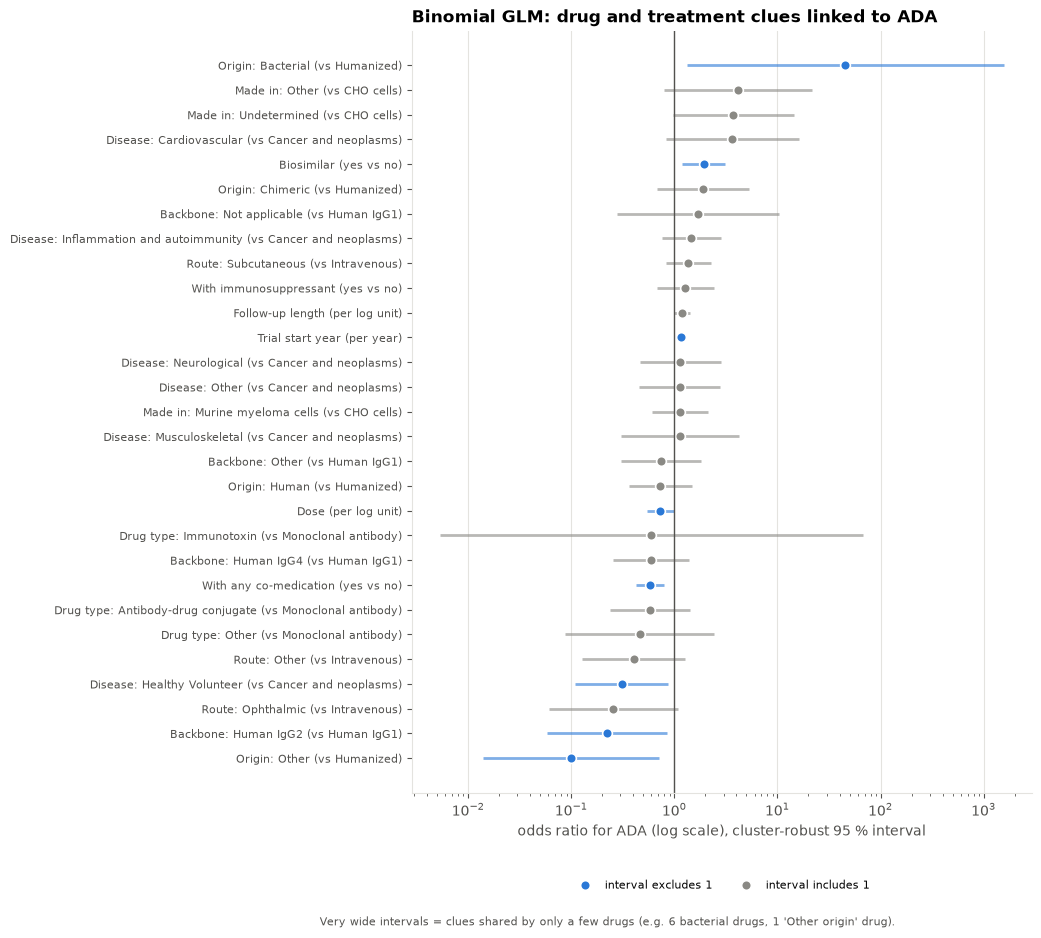

In [ ]:
FEATURE_LABEL = {"route": "Route", "indication": "Disease", "modality": "Drug type", "species": "Origin",
                 "backbone": "Backbone", "expression": "Made in", "blinding": "Blinding", "randomized": "Randomised",
                 "comparator": "Comparator"}
SINGLE = {"log_dose_mgkg": "Dose (per log unit)", "start_year": "Trial start year (per year)",
          "log_followup_days": "Follow-up length (per log unit)", "co_immunosuppressant": "With immunosuppressant (yes vs no)",
          "co_any_drug": "With any co-medication (yes vs no)", "arm_mentions_placebo": "Arm mentions placebo",
          "biosimilar": "Biosimilar (yes vs no)"}

def nice(col):
    """'species_Chimeric' -> 'Origin: Chimeric (vs Humanized)'."""
    if col in SINGLE:
        return SINGLE[col]
    feat = next(c for c in im.CAT_FEATURES if col.startswith(c + "_"))
    ref = im.REFERENCE[feat].replace("Chinese hamster ovary (CHO) cells", "CHO cells")
    return f"{FEATURE_LABEL[feat]}: {col[len(feat) + 1:]} (vs {ref})"

# The figure shows drug, treatment and patient clues; study-design clues stay in the table above.
DESIGN = ("blinding_", "randomized_", "comparator_", "missingindicator_", "arm_mentions_placebo")
f = OR.loc[[r for r in OR.index if not r.startswith(DESIGN)]].sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(8, 0.3 * len(f) + 1.2))
yy = np.arange(len(f))
sig = f["p_cluster"] < 0.05
ax.hlines(yy, f.CI_low, f.CI_high, color=np.where(sig, BLUE, GRAY), lw=2, alpha=0.6)
ax.plot(f.odds_ratio[sig], yy[sig], "o", color=BLUE, ms=7, mec="white", mew=1.2, label="interval excludes 1")
ax.plot(f.odds_ratio[~sig], yy[~sig], "o", color=GRAY, ms=7, mec="white", mew=1.2, label="interval includes 1")
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale("log"); ax.set_yticks(yy, [nice(r) for r in f.index], fontsize=8)
ax.set_xlabel("odds ratio for ADA (log scale), cluster-robust 95 % interval")
ax.set_title("Binomial GLM: drug and treatment clues linked to ADA"); ax.grid(axis="y", visible=False)
fig.text(0.01, -0.01 - 0.4 / len(f), "Very wide intervals = clues shared by only a few drugs (e.g. 6 bacterial drugs, 1 'Other origin' drug).", fontsize=8, color=INK2)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08 - 0.6 / len(f)), ncol=2)
fig.savefig(ROOT / "figures" / "glm_forest.png"); plt.show()

## 4 · How well does it predict NEW drugs? (grouped CV)

Same 5 folds and same scores as the baselines in notebook 04.

In [ ]:
def naive(train, test):
    return np.full(len(test), train["y"].sum() / train["n"].sum())

def glm_plain(train, test):
    pre, params = im.fit_glm(train)
    return im.predict_glm(pre, params, test)

rows = {}
for name, fn in [("naive baseline", naive), ("GLM (plain)", glm_plain)]:
    for split in ["fold_grouped", "fold_random"]:
        per_fold, oof = im.cross_validate(df, split, fn)
        rows[(name, split)] = per_fold
        if split == "fold_grouped":
            im.save_results({"naive baseline": "naive", "GLM (plain)": "glm_plain"}[name], per_fold, oof, df, ROOT)

def summary_table(rows):
    out = []
    for (name, split), pf in rows.items():
        m, s = pf.drop(columns="fold").mean(), pf.drop(columns="fold").std()
        out.append({"model": name, "split": "grouped (honest)" if split == "fold_grouped" else "random (leaky)",
                    "wMAE": m.wMAE, "wMAE_sd": s.wMAE, "wRMSE": m.wRMSE, "wRMSE_sd": s.wRMSE, "loglik": m.loglik, "loglik_sd": s.loglik})
    return pd.DataFrame(out)

tab = summary_table(rows)
display(tab.style.format({c: "{:.3f}" for c in tab.columns if c not in ("model", "split")}).hide(axis="index"))
print("per-fold wMAE, plain GLM (grouped):", rows[("GLM (plain)", "fold_grouped")]["wMAE"].round(3).tolist())
print("per-fold wMAE, naive     (grouped):", rows[("naive baseline", "fold_grouped")]["wMAE"].round(3).tolist())

model,split,wMAE,wMAE_sd,wRMSE,wRMSE_sd,loglik,loglik_sd
naive baseline,grouped (honest),0.131,0.037,0.183,0.060,-17.821,8.909
naive baseline,random (leaky),0.133,0.016,0.190,0.031,-17.349,4.969
GLM (plain),grouped (honest),0.161,0.033,0.230,0.041,-33.417,18.485
GLM (plain),random (leaky),0.109,0.012,0.156,0.020,-12.836,4.002


per-fold wMAE, plain GLM (grouped): [0.131, 0.197, 0.14, 0.198, 0.14]
per-fold wMAE, naive     (grouped): [0.118, 0.186, 0.127, 0.141, 0.085]


**Why can the plain GLM lose to "always guess the average"?**
1. It has 42 weights but only ~86 *molecules* to learn from in each training fold, and molecules (not cohorts) are the real units of information. So it **overfits**.
2. Because of overdispersion, it trusts big cohorts far too much: one 10,000-patient trial pulls the weights as if it were 10,000 independent coin flips.
3. Rare levels (e.g. a category with 1–2 drugs) get extreme weights that blow up when a new drug shares that level.

The fix is to **shrink** the weights towards zero: **regularisation**.

## 5 · Regularisation (an optimisation trade-off)

We maximise *log-likelihood − penalty*:

* **L2 / ridge:** penalty = α·Σβ². Shrinks all weights smoothly; keeps every feature.
* **L1 / lasso:** penalty = α·Σ|β|. Pushes many weights to **exactly zero** = automatic **feature selection**.

Bigger α = more shrinking. α → ∞ gives the naive baseline (all weights 0, intercept only).

### 5a · The regularisation path (for illustration)

In [ ]:
ALPHAS = [0.1, 0.3, 1, 3, 10, 30]
path = []
for L1_wt, label in [(0.0, "L2 (ridge)"), (1.0, "L1 (lasso)")]:
    for a in ALPHAS:
        nz = []
        def fn(train, test, a=a, L1_wt=L1_wt):
            pre, params = im.fit_glm(train, alpha=a, L1_wt=L1_wt)
            nz.append(int((np.abs(params[1:]) > 1e-8).sum()))
            return im.predict_glm(pre, params, test)
        pf, _ = im.cross_validate(df, "fold_grouped", fn)
        path.append({"penalty": label, "alpha": a, **pf.drop(columns="fold").mean().to_dict(), "features_kept": np.mean(nz)})
path = pd.DataFrame(path)
display(path.style.format({"wMAE": "{:.4f}", "wRMSE": "{:.4f}", "loglik": "{:.2f}", "features_kept": "{:.0f}"}).hide(axis="index"))

penalty,alpha,wMAE,wRMSE,loglik,features_kept
L2 (ridge),0.100000,0.1460,0.2028,-23.68,42
L2 (ridge),0.300000,0.1408,0.1942,-21.76,42
L2 (ridge),1.000000,0.1357,0.1856,-19.86,42
L2 (ridge),3.000000,0.1322,0.1801,-18.45,42
L2 (ridge),10.000000,0.1299,0.1782,-17.55,42
L2 (ridge),30.000000,0.1302,0.1793,-17.36,42
L1 (lasso),0.100000,0.1460,0.2017,-23.53,24
L1 (lasso),0.300000,0.1403,0.1939,-20.82,18
L1 (lasso),1.000000,0.1328,0.1813,-18.47,9
L1 (lasso),3.000000,0.1312,0.1803,-17.61,4


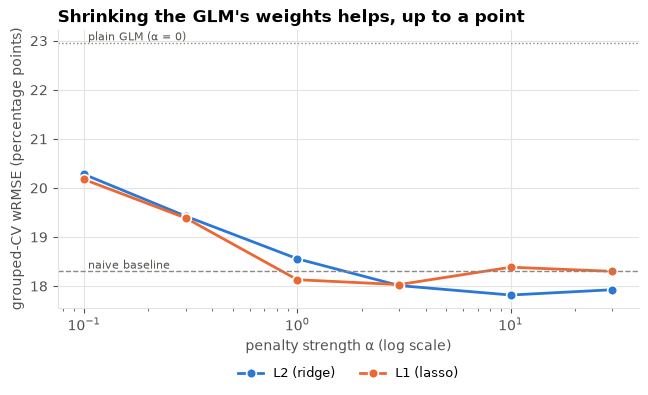

In [ ]:
naive_rmse = tab.query("model == 'naive baseline' and split == 'grouped (honest)'")["wRMSE"].item()
plain_rmse = tab.query("model == 'GLM (plain)' and split == 'grouped (honest)'")["wRMSE"].item()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for label, color in [("L2 (ridge)", BLUE), ("L1 (lasso)", ORANGE)]:
    p = path[path.penalty == label]
    ax.plot(p.alpha, p.wRMSE * 100, "o-", color=color, lw=2, ms=7, mec="white", mew=1.2, label=label)
ax.axhline(naive_rmse * 100, color=GRAY, ls="--", lw=1); ax.text(ALPHAS[0], naive_rmse * 100, " naive baseline", va="bottom", color=INK2, fontsize=8)
ax.axhline(plain_rmse * 100, color=GRAY, ls=":", lw=1); ax.text(ALPHAS[0], plain_rmse * 100, " plain GLM (α = 0)", va="bottom", color=INK2, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("penalty strength α (log scale)"); ax.set_ylabel("grouped-CV wRMSE (percentage points)")
ax.set_title("Shrinking the GLM's weights helps, up to a point")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
fig.savefig(ROOT / "figures" / "glm_regularisation_path.png"); plt.show()

### 5b · Honest tuning: nested CV

Picking α by looking at the curve above uses the test folds to choose, which is a subtle leak. The honest way:
**inside each training fold**, run a second grouped CV to choose α; then score that choice on the untouched test fold.

In [ ]:
def make_tuned_glm(L1_wt, alphas=ALPHAS, inner_splits=4):
    chosen = []
    def fn(train, test):
        inner = GroupKFold(n_splits=inner_splits)
        best_a, best_ll = None, -np.inf
        for a in alphas:
            lls = []
            for tr_idx, va_idx in inner.split(train, groups=train[im.GROUP]):
                tr, va = train.iloc[tr_idx], train.iloc[va_idx]
                pre, params = im.fit_glm(tr, alpha=a, L1_wt=L1_wt)
                lls.append(im.mean_loglik(va["y"], va["n"], im.predict_glm(pre, params, va)))
            if np.mean(lls) > best_ll:
                best_a, best_ll = a, np.mean(lls)
        chosen.append(best_a)
        pre, params = im.fit_glm(train, alpha=best_a, L1_wt=L1_wt)
        return im.predict_glm(pre, params, test)
    return fn, chosen

for name, key, L1_wt in [("GLM + L2 (tuned)", "glm_l2", 0.0), ("GLM + L1 (tuned)", "glm_l1", 1.0)]:
    fn, chosen = make_tuned_glm(L1_wt)
    pf, oof = im.cross_validate(df, "fold_grouped", fn)
    rows[(name, "fold_grouped")] = pf
    im.save_results(key, pf, oof, df, ROOT)
    print(f"{name}: α chosen in each outer fold = {chosen}")

tab = summary_table({k: v for k, v in rows.items() if k[1] == "fold_grouped"})
display(tab.style.format({c: "{:.3f}" for c in tab.columns if c not in ("model", "split")}).hide(axis="index"))

GLM + L2 (tuned): α chosen in each outer fold = [30, 1, 10, 30, 30]


GLM + L1 (tuned): α chosen in each outer fold = [30, 30, 3, 10, 3]


model,split,wMAE,wMAE_sd,wRMSE,wRMSE_sd,loglik,loglik_sd
naive baseline,grouped (honest),0.131,0.037,0.183,0.060,-17.821,8.909
GLM (plain),grouped (honest),0.161,0.033,0.230,0.041,-33.417,18.485
GLM + L2 (tuned),grouped (honest),0.132,0.039,0.183,0.062,-18.671,9.964
GLM + L1 (tuned),grouped (honest),0.135,0.038,0.188,0.059,-18.963,9.126


## 6 · Which features does the lasso keep? (feature selection)
We refit the L1 model on **all** cohorts at the α chosen most often, and list the survivors.

In [ ]:
from collections import Counter
fn, chosen = make_tuned_glm(1.0)
_ = fn(df, df.iloc[:1])                               # run the inner tuning on all data
a_star = chosen[0]
pre, params = im.fit_glm(df, alpha=a_star, L1_wt=1.0)
names = pre.get_feature_names_out()
kept = pd.Series(params[1:], index=names)[lambda s: s.abs() > 1e-8].sort_values()
print(f"α = {a_star}: lasso keeps {len(kept)} of {len(names)} features (weights on the standardised scale):")
display(kept.rename("weight").to_frame().assign(direction=lambda t: np.where(t.weight > 0, "↑ more ADA", "↓ less ADA")))

α = 3: lasso keeps 4 of 42 features (weights on the standardised scale):


,weight,direction
missingindicator_log_followup_days,-0.049184,↓ less ADA
missingindicator_start_year,0.011676,↑ more ADA
start_year,0.097661,↑ more ADA
biosimilar,0.213351,↑ more ADA


## 7 · Sensitivity checks: do the main conclusions survive?

1. **Only cohorts with n ≥ 20** (drop small, noisy cohorts).
2. **Latest timepoint** instead of peak ADA per cohort (notebook 02).

We compare cluster-robust odds ratios for the key features.

In [ ]:
def cluster_or(data):
    pre = im.make_preprocessor(scale=False).fit(data)
    Xs = sm.add_constant(pd.DataFrame(pre.transform(data), columns=pre.get_feature_names_out()))
    r = sm.GLM(np.column_stack([data["y"], data["n"] - data["y"]]), Xs, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(data[im.GROUP])[0]})
    c = r.conf_int()
    return pd.DataFrame({"OR": np.exp(r.params), "lo": np.exp(c[0]), "hi": np.exp(c[1])})

latest = im.load_cohorts(ROOT, which="latest")
KEY = ["species_Chimeric", "species_Human", "modality_Immunotoxin", "route_Subcutaneous",
       "indication_Inflammation and autoimmunity", "co_immunosuppressant", "start_year", "log_dose_mgkg", "log_followup_days"]
sens = {}
for label, data in [("main (peak, all n)", df), ("n ≥ 20 only", df[df["n"] >= 20]), ("latest timepoint", latest)]:
    t = cluster_or(data)
    sens[label] = t.reindex(KEY).apply(lambda r: f"{r.OR:.2f} [{r.lo:.2f}–{r.hi:.2f}]", axis=1)
    print(f"{label:20s} cohorts = {len(data)}")
display(pd.DataFrame(sens).rename(index=nice))

main (peak, all n)   cohorts = 1754
n ≥ 20 only          cohorts = 1187


latest timepoint     cohorts = 1754


,"main (peak, all n)",n ≥ 20 only,latest timepoint
Origin: Chimeric (vs Humanized),1.90 [0.68–5.29],1.94 [0.69–5.48],1.99 [0.67–5.92]
Origin: Human (vs Humanized),0.73 [0.36–1.48],0.75 [0.37–1.55],0.72 [0.36–1.42]
Drug type: Immunotoxin (vs Monoclonal antibody),0.60 [0.01–67.18],0.98 [0.01–127.04],8.20 [0.19–361.14]
Route: Subcutaneous (vs Intravenous),1.37 [0.83–2.25],1.36 [0.81–2.30],1.38 [0.84–2.27]
Disease: Inflammation and autoimmunity (vs Cancer and neoplasms),1.46 [0.76–2.83],1.53 [0.78–2.99],1.34 [0.67–2.68]
With immunosuppressant (yes vs no),1.27 [0.68–2.40],1.27 [0.67–2.40],1.41 [0.76–2.65]
Trial start year (per year),1.15 [1.07–1.24],1.16 [1.07–1.25],1.16 [1.07–1.25]
Dose (per log unit),0.73 [0.54–0.99],0.73 [0.54–1.00],0.75 [0.54–1.03]
Follow-up length (per log unit),1.18 [0.99–1.42],1.19 [0.98–1.44],1.14 [0.94–1.37]


## 8 · Day 5 findings (write-up)

> **Correction note (Day 11):** CV folds and cluster-robust errors are now grouped by **molecule** (biosimilars kept together) instead of by product. All numbers below are from the corrected run.

**1. Overdispersion confirmed.** Even with all 42 features, the GLM's dispersion is **≈ 22** (it should be ≈ 1). The plain GLM's p-values are therefore far too optimistic: **40 of 42** features look "significant" with naive standard errors, but only **10 of 42** do with honest **cluster-by-molecule** errors. This is the strongest argument for the Beta-Binomial model (Day 10).

**2. What the GLM associates with ADA** (odds ratios, cluster-robust 95 % CI, holding other clues fixed):
* **Trial start year:** OR **1.15 per year** [1.07–1.24]. Later trials report more ADA, consistent with more sensitive assays. This is the most robust finding.
* **Dose:** OR **0.73 per log unit** [0.54–0.99]. Higher doses are linked with *less* ADA, consistent with "high-dose tolerance" (and drug interfering with older assays).
* **Any co-medication:** OR **0.58** [0.43–0.80]. **Biosimilar:** OR **1.93** [1.20–3.10] (biosimilar trials often use newer, more sensitive head-to-head assays).
* **Active-controlled trials:** OR **2.6** [1.3–5.2], likely biosimilar head-to-head trials of high-ADA drugs.
* **IgG2 backbone vs IgG1:** OR **0.22** [0.06–0.85]; **healthy volunteers vs cancer:** OR **0.31** [0.11–0.88].
* **Bacterial origin vs humanized:** OR ≈ 45 but [1.3–1560]. It is very large and very uncertain, because there are only 6 drugs.
* **Not clearly different once other clues are included:** longer follow-up (1.18 [0.99–1.42]), eye vs IV route (0.26 [0.06–1.07]), chimeric vs humanized (1.9 [0.7–5.3]), fully human vs humanized (0.73), subcutaneous vs IV (1.37 [0.8–2.3]), autoimmune vs cancer (1.46), immunosuppressant (1.27). Directions mostly match biology, but the information comes from relatively few molecules.

**3. Prediction for new molecules is hard.** Grouped CV (unseen molecules):

| model | wMAE | wRMSE | loglik |
|---|---|---|---|
| naive baseline | 0.131 | 0.183 | −17.8 |
| plain GLM | 0.161 | 0.230 | −33.4 |
| GLM + L2 (α tuned in nested CV) | 0.132 | 0.183 | −18.7 |
| GLM + L1 (α tuned in nested CV) | 0.135 | 0.188 | −19.0 |

The **plain GLM is worse than guessing the average**: it overfits ~86 training molecules with 42 weights and trusts giant cohorts as if every patient were independent. Under a *random* (leaky) split the same GLM looks good (wMAE 0.109), which is another example of leakage. **Regularisation** brings it back to baseline level. The best fixed penalty (L2, α ≈ 10) reaches wRMSE 0.178, but once α is chosen honestly the gain disappears. Overall, **the GLM does not beat the baseline for new molecules**.

**4. Feature selection (lasso):** at the tuned penalty, only **4 of 42** features survive: trial start year, biosimilar, and two missing-data flags. The data support only a few strong, drug-independent signals.

**5. Sensitivity:** odds ratios are almost identical with **n ≥ 20 only** and with the **latest timepoint** (start year 1.15 → 1.16 / 1.16; dose 0.73 → 0.73 / 0.75), so the conclusions don't depend on the small cohorts or the peak-timepoint choice.

**Honest take-away:** a linear model on trial and drug-label clues explains *some* patterns (assay era, dose, a few drug classes), but **most variation in ADA is molecule-specific** and not captured by these clues.